# 01 · Exploratory Data Analysis: UCI Heart Disease (Cleveland)

**Goal:** understand the data before modelling: quality issues, class balance, and which clinical signals separate patients with and without heart disease.

**Source:** UCI Machine Learning Repository, dataset #45 (`processed.cleveland.data`, 303 patients, 13 clinical features + diagnosis). The raw `num` field (0-4) is binarised to `target` = 1 when any disease is present.

All plotting code lives in `cardiorisk/eda.py`, so this notebook and the CLI (`python -m cardiorisk.eda`) produce identical figures.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from cardiorisk import config, eda
from cardiorisk.data import clean, download, load_raw, summarise, validate

%matplotlib inline
eda.set_style()
pd.set_option('display.precision', 2)

## 1. Acquisition and cleaning

`download()` fetches the file (falling back to the UCI zip archive) and checks its SHA-256 so every run uses byte-identical input. `clean()` then:

1. parses `?` as missing and coerces every column to numeric,
2. binarises the target (`num > 0`),
3. sets physiologically implausible values and invalid category codes to missing,
4. removes exact duplicate rows.

Missing values are **not** imputed here. Imputation lives inside the model pipeline and is fitted on training folds only, which avoids leaking test-set statistics.

In [2]:
raw = load_raw(download())
df = clean(raw)
validate(df)
print(f'raw shape: {raw.shape}  ->  clean shape: {df.shape}')
summarise(df)

raw shape: (303, 14)  ->  clean shape: (303, 14)


{'rows': 303,
 'features': 13,
 'missing_values': {'ca': 4, 'thal': 2},
 'class_counts': {0: 164, 1: 139},
 'positive_rate': 0.4587}

In [3]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## 2. Data quality: missing values

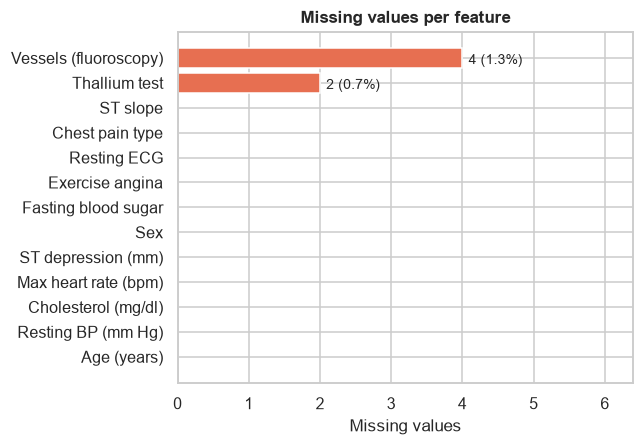

In [5]:
eda.plot_missing_values(df);

Only `ca` (4 rows) and `thal` (2 rows) have gaps, about 2% of patients. Dropping them would be cheap, but the deployed API must also cope with a clinician leaving these fields blank, so the pipeline imputes them (median for `ca`, most frequent for `thal`) and the API accepts them as optional.

## 3. Target class balance

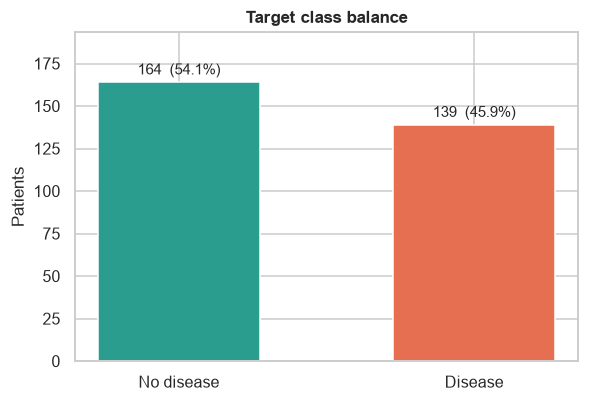

In [6]:
eda.plot_class_balance(df);

164 negative vs 139 positive (46% positive): mildly imbalanced. Stratified splits and stratified K-fold keep this ratio in every fold, and `class_weight='balanced'` is included in the tuning grid rather than assumed.

## 4. Continuous features by diagnosis

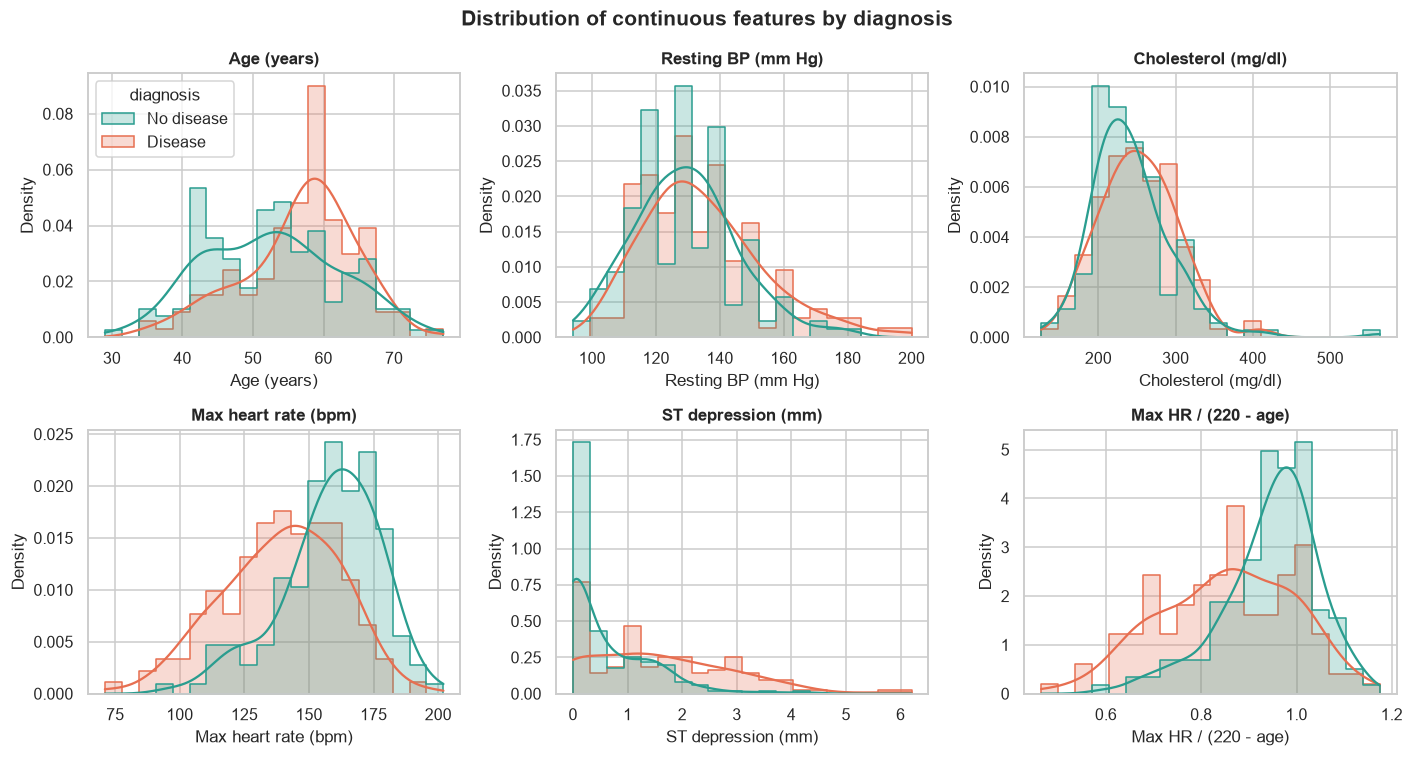

In [7]:
eda.plot_numeric_distributions(df);

In [8]:
df.assign(pct_max_hr=df.thalach / (220 - df.age)).groupby('target')[['age', 'thalach', 'oldpeak', 'pct_max_hr', 'chol', 'trestbps']].median()

,age,thalach,oldpeak,pct_max_hr,chol,trestbps
target,,,,,,
0,52.0,161.0,0.2,0.96,234.5,130.0
1,58.0,142.0,1.4,0.87,249.0,130.0


* **Max heart rate** (`thalach`) is clearly lower in diseased patients (median 142 vs 161 bpm), and **ST depression** (`oldpeak`) is higher (1.4 vs 0.2).
* Diseased patients are older (median 58 vs 52). Because max heart rate naturally falls with age, part of the `thalach` signal is an age effect. The engineered ratio `thalach / (220 - age)`, the share of age-predicted maximum heart rate reached, separates the classes in its own right (0.87 vs 0.96).
* Cholesterol and resting BP overlap heavily; they are weak on their own.
* `oldpeak` is right-skewed with many zeros, and `chol` has a far outlier (~560 mg/dl) that is plausible, so it is kept. Standard scaling is applied for the linear model.

## 5. Correlation structure

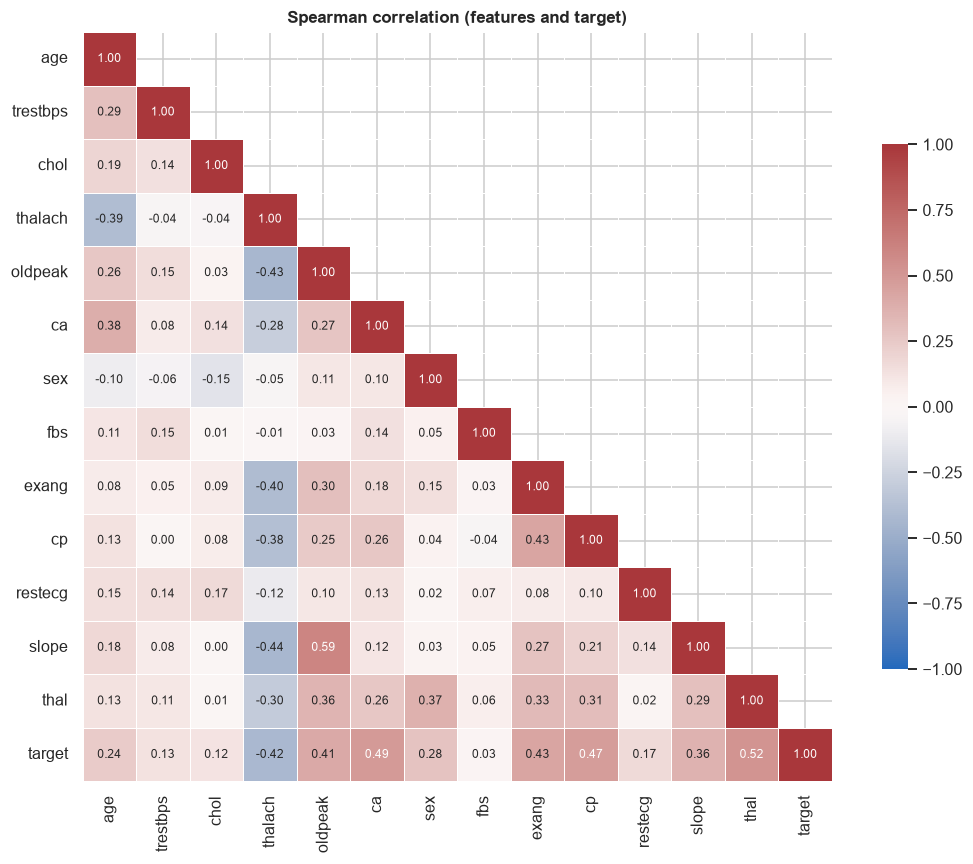

In [9]:
eda.plot_correlation_heatmap(df);

In [10]:
df.corr(method='spearman')['target'].drop('target').sort_values(key=abs, ascending=False).to_frame('spearman_rho')

,spearman_rho
thal,0.52
ca,0.49
cp,0.47
exang,0.43
thalach,-0.42
oldpeak,0.41
slope,0.36
sex,0.28
age,0.24
restecg,0.17


Spearman (rank) correlation is used because most features are ordinal or skewed. The strongest associations with the target come from the stress-test and imaging features: `thal` (0.52), `ca` (0.49), `cp` (0.47), `exang` (0.43), `oldpeak` (0.41) and `thalach` (-0.42). `fbs` is essentially uninformative (0.03). No pair of features is correlated strongly enough (|rho| > 0.6) to cause harmful collinearity, so all 13 features are kept and L1/L2 regularisation is left to the tuning step.

## 6. Categorical features: disease rate per category

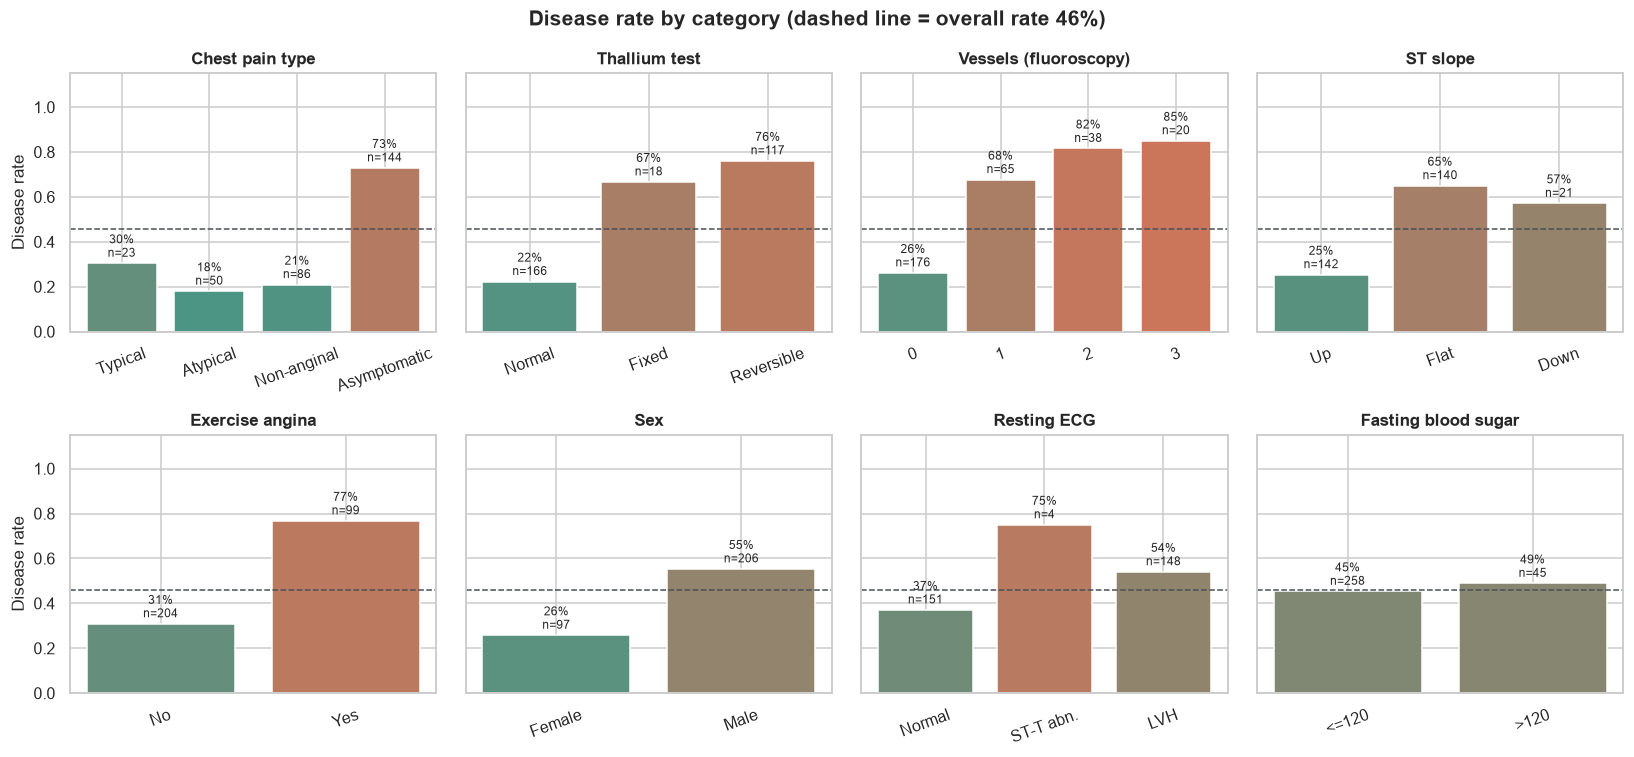

In [11]:
eda.plot_categorical_risk(df);

* **Asymptomatic chest pain** (`cp=4`) carries a 73% disease rate, versus 18-30% for the other chest-pain types.
* **Reversible thallium defect** (76%) and **one or more vessels on fluoroscopy** (68-85%) are strong markers.
* `restecg=1` has only 4 patients, so its rate is unreliable. One-hot encoding uses `handle_unknown='ignore'` so unseen or rare codes never break inference.
* These codes are nominal, not ordinal (for example `thal` = 3/6/7), so they are one-hot encoded rather than used as numbers.

## 7. Heart-rate response vs age

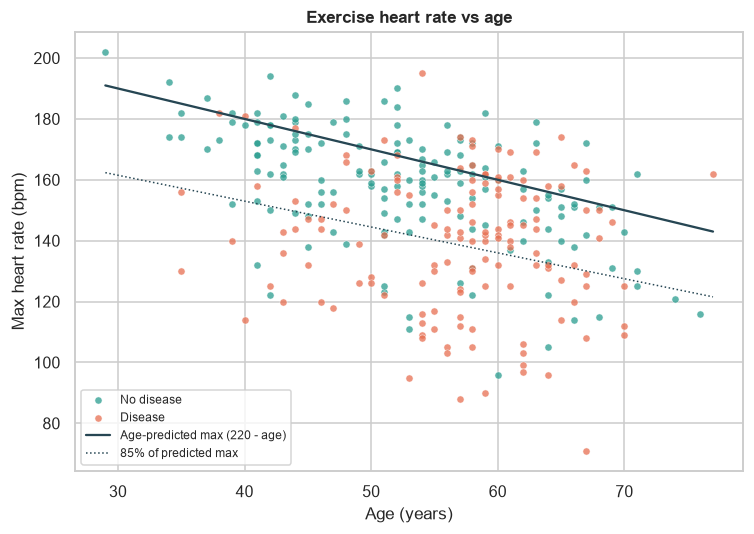

In [12]:
eda.plot_heart_rate_vs_age(df);

Diseased patients cluster below the 85% line of age-predicted maximum heart rate (a common clinical threshold for an adequate stress test). This motivates the two engineered features added in the model pipeline:

| Feature | Definition | Rationale |
|---|---|---|
| `pct_max_hr` | `thalach / (220 - age)` | Age-normalised exercise heart-rate response |
| `bp_stage` | ACC/AHA 2017 stage from `trestbps` (0-3) | Clinically meaningful bands instead of raw mm Hg |

## 8. Summary and implications for modelling

| Finding | Decision |
|---|---|
| 6 missing values in `ca` / `thal` | Impute inside the pipeline (fitted per fold) |
| 46% positive class | Stratified 80/20 split + stratified 5-fold CV; tune `class_weight` |
| Nominal codes (`cp`, `thal`, `slope`, `restecg`) | One-hot encode |
| Different numeric scales, skewed `oldpeak` | Standard scaling |
| Strong, partly non-linear signals | Compare a linear model with tree ensembles |
| Heart rate depends on age | Engineer `pct_max_hr`; add `bp_stage` |

Figures are also written to `reports/figures/` by `python -m cardiorisk.eda` for the final report.